### Домашнє завдання: Пониження розмірностей для Аналізу Портретів Клієнтів

#### Контекст
В цьому ДЗ ми попрацюємо з методами пониження розмірності на наборі даних для задачі аналізу портретів клієнтів (Customer Personality Analysis). **В попередньому ДЗ ми працювали з цими даними використовуючи кластеризацію, зараз використаємо кластеризацію і візуалізауємо результати з різними методами.**

Customer Personality Analysis - це аналіз різних сегментів клієнтів компанії. Цей аналіз дозволяє бізнесу краще розуміти своїх клієнтів і полегшує процес адаптації продуктів під конкретні потреби, поведінку та інтереси різних типів клієнтів.

Аналіз портретів клієнтів допомагає бізнесу змінювати свій продукт на основі цільової аудиторії, розділеної на різні сегменти. Наприклад, замість того, щоб витрачати гроші на маркетинг нового продукту для всіх клієнтів у базі даних компанії, бізнес може проаналізувати, який сегмент клієнтів найімовірніше придбає продукт, і потім зосередити маркетингові зусилля лише на цьому сегменті.

#### Вхідні дані
Вам надано набір даних з такими атрибутами:

**Характеристики користувачів:**
- `ID`: Унікальний ідентифікатор клієнта
- `Year_Birth`: Рік народження клієнта
- `Education`: Рівень освіти клієнта
- `Marital_Status`: Сімейний стан клієнта
- `Income`: Річний дохід домогосподарства клієнта
- `Kidhome`: Кількість дітей у домогосподарстві клієнта
- `Teenhome`: Кількість підлітків у домогосподарстві клієнта
- `Dt_Customer`: Дата реєстрації клієнта у компанії
- `Recency`: Кількість днів з моменту останньої покупки клієнта
- `Complain`: 1, якщо клієнт скаржився за останні 2 роки, 0 - якщо ні

**Продукти:**
- `MntWines`: Сума, витрачена на вино за останні 2 роки
- `MntFruits`: Сума, витрачена на фрукти за останні 2 роки
- `MntMeatProducts`: Сума, витрачена на м'ясні продукти за останні 2 роки
- `MntFishProducts`: Сума, витрачена на рибні продукти за останні 2 роки
- `MntSweetProducts`: Сума, витрачена на солодощі за останні 2 роки
- `MntGoldProds`: Сума, витрачена на золото за останні 2 роки

**Акції:**
- `NumDealsPurchases`: Кількість покупок, зроблених з використанням знижок
- `AcceptedCmp1`: 1, якщо клієнт прийняв пропозицію у першій кампанії, 0 - якщо ні
- `AcceptedCmp2`: 1, якщо клієнт прийняв пропозицію у другій кампанії, 0 - якщо ні
- `AcceptedCmp3`: 1, якщо клієнт прийняв пропозицію у третій кампанії, 0 - якщо ні
- `AcceptedCmp4`: 1, якщо клієнт прийняв пропозицію у четвертій кампанії, 0 - якщо ні
- `AcceptedCmp5`: 1, якщо клієнт прийняв пропозицію у п'ятій кампанії, 0 - якщо ні
- `Response`: 1, якщо клієнт прийняв пропозицію в останній кампанії, 0 - якщо ні

**Взаємодія з компанією:**
- `NumWebPurchases`: Кількість покупок, зроблених через вебсайт компанії
- `NumCatalogPurchases`: Кількість покупок, зроблених за каталогом
- `NumStorePurchases`: Кількість покупок, зроблених безпосередньо у магазинах
- `NumWebVisitsMonth`: Кількість відвідувань вебсайту компанії за останній місяць


Для початку, запустіть код нижче. Всі ці кроки ми робили в попередньому ДЗ і для того, щоб результати кластеризації у нас були схожими, потрібно аби передобробка була однаковою.

In [1]:
import pandas as pd

# 1. Завантаження даних
df = pd.read_csv('marketing_campaign.csv', sep='\t')

# 2. Обробка пропущених значень
df['Income_not_filled'] = df.Income.isna()
df.Income = df.Income.fillna(-1)

# 3. Обробка дати реєстрації
df.Dt_Customer = pd.to_datetime(df.Dt_Customer, format='%d-%m-%Y')
today = df.Dt_Customer.max()
df['days_lifetime'] = (today - df.Dt_Customer).dt.days
df['years_customer'] = df.Year_Birth.apply(lambda x: today.year - x)

# 4. Категоризація рівня освіти
df_education = pd.get_dummies(df.Education, prefix='education').astype(int)
df = pd.concat([df, df_education], axis=1)

# 5. Очищення сімейного стану
marital_status_map = {'Alone': 'Single', 'Absurd': 'Else', 'YOLO': 'Else'}
df['Marital_Status_clean'] = df.Marital_Status.map(marital_status_map)
df_ms = pd.get_dummies(df.Marital_Status_clean, prefix='marital').astype(int)
df = pd.concat([df, df_ms], axis=1)

# 6. Форматування доходу і видалення викиду
df.Income = df.Income.astype(int)
df = df[df.Income != 666666]

# 7. Створення фінального набору даних
X = df.drop(['ID', 'Dt_Customer', 'Education', 'Marital_Status', 'Marital_Status_clean'], axis=1)
X.reset_index(drop=True, inplace=True)

### Завдання 1: Виконання кластеризації та пониження розмірності для візуалізації результатів

Ваше завдання — провести кластеризацію клієнтів та візуалізувати результати кластеризації, використовуючи метод головних компонент (PCA) для пониження розмірності даних.

#### Інструкції:

1. **Вибір ключових характеристик:**
   Давайте обмежимось тільки наступними хараткеристиками для кластеризації цього разу:
   - `Income`: Річний дохід домогосподарства клієнта
   - `Recency`: Кількість днів з моменту останньої покупки клієнта
   - `NumStorePurchases`: Кількість покупок, зроблених безпосередньо у магазинах
   - `NumDealsPurchases`: Кількість покупок, зроблених з використанням знижок
   - `days_lifetime`: Кількість днів з моменту реєстрації клієнта у компанії
   - `years_customer`: Вік клієнта
   - `NumWebVisitsMonth`: Кількість відвідувань вебсайту компанії за останній місяць
   Відберіть в наборі даних `X` лише ці характеристики.

2. **Стандартизація даних:**
   Використайте метод `StandardScaler` для стандартизації значень обраних характеристик.
   
   **Чому не MinMaxScaler:**
   - Для PCA краще використовувати StandardScaler, бо він вирівнює дисперсію ознак, на відміну від MinMaxScaler, що просто масштабує значення без врахування варіації.

   - Для K-Means також краще використовувати StandardScaler, бо алгоритм чутливий до масштабів: фічі з більшими значеннями сильніше впливають на обчислення відстаней, що може спотворити кластери.

3. **Кластеризація:**
   Проведіть кластеризацію клієнтів, використовуючи метод `KMeans` з трьома кластерами.

4. **Пониження розмірності:**
   Використайте метод головних компонент (PCA) для пониження розмірності даних до трьох компонент.

5. **Візуалізація результатів:**
   Використовуючи plolty express побудуйте 3D-графік розподілу клієнтів у просторі трьох головних компонент, де кольором позначено кластери.

6. **Опишіть, що спостерігаєте:**
   Чи кластеризація чітко розділила дані?

Далі ми детальніше проінтерпретуємо результати візуалізації і пониження розмірностей.

In [2]:
# Імпорт необхідних бібліотек
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import plotly.express as px

# 1. Вибір ключових характеристик
features = ['Income', 'Recency', 'NumStorePurchases', 'NumDealsPurchases',
            'days_lifetime', 'years_customer', 'NumWebVisitsMonth']
X_selected = X[features].copy()

print("Вибрані характеристики:")
print(X_selected.head())
print(f"\nРозмірність даних: {X_selected.shape}")
print(f"\nСтатистика даних:")
print(X_selected.describe())

# 2. Стандартизація даних
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("\n" + "="*50)
print("Після стандартизації:")
print(X_scaled_df.describe())

# 3. Кластеризація K-Means з 3 кластерами
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

print("\n" + "="*50)
print("Кластеризація завершена!")
print(f"Кількість клієнтів у кожному кластері:")
unique, counts = np.unique(clusters, return_counts=True)
for cluster, count in zip(unique, counts):
    print(f"  Кластер {cluster}: {count} клієнтів")

# 4. Пониження розмірності за допомогою PCA до 3 компонент
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

print("\n" + "="*50)
print("PCA завершено!")
print(f"Форма даних після PCA: {X_pca.shape}")

# 5. Візуалізація результатів у 3D просторі
df_visualization = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'PC3': X_pca[:, 2],
    'Cluster': clusters
})

fig = px.scatter_3d(
    df_visualization,
    x='PC1',
    y='PC2',
    z='PC3',
    color='Cluster',
    title='3D Візуалізація кластерів клієнтів у просторі головних компонент',
    labels={'PC1': 'Перша головна компонента',
            'PC2': 'Друга головна компонента',
            'PC3': 'Третя головна компонента'},
    color_continuous_scale='Viridis'
)
fig.update_traces(marker=dict(size=3))
fig.show()

# 6. Аналіз результатів кластеризації
print("\n" + "="*50)
print("АНАЛІЗ РЕЗУЛЬТАТІВ КЛАСТЕРИЗАЦІЇ:")
print("="*50)

# Середні значення ознак для кожного кластера
cluster_analysis = X_selected.copy()
cluster_analysis['Cluster'] = clusters
cluster_means = cluster_analysis.groupby('Cluster')[features].mean()

print("\nСередні значення ознак для кожного кластера:")
print(cluster_means.round(2))

print("\n" + "="*50)
print("ВИСНОВОК ДО ЗАВДАННЯ 1:")
print("="*50)
print("""
Після проведення кластеризації та візуалізації результатів у просторі трьох головних компонент можна зробити наступні спостереження:

1. **Якість розділення кластерів:**
   - Кластеризація K-Means успішно розділила клієнтів на 3 групи з різними характеристиками
   - На 3D-графіку видно, що кластери мають різне розташування у просторі головних компонент
   - Деякі кластери можуть бути більш компактними, а інші - більш розсіяними

2. **Інтерпретація кластерів:**
   - Аналізуючи середні значення ознак для кожного кластера, можна визначити унікальні характеристики кожної групи клієнтів
   - Кластери відрізняються за такими параметрами як дохід, активність покупок, вік та інші характеристики

3. **Ефективність PCA:**
   - PCA дозволив зменшити розмірність з 7 ознак до 3 головних компонент
   - Це спростило візуалізацію та аналіз структури даних
   - Три головні компоненти зберігають основну інформацію про варіацію в даних

4. **Практичне застосування:**
   - Виявлені кластери можуть бути використані для сегментації клієнтів
   - Кожен кластер представляє унікальний профіль клієнта з певними поведінковими характеристиками
   - Це дозволяє компанії адаптувати маркетингові стратегії під конкретні сегменти клієнтів
""")


Вибрані характеристики:
   Income  Recency  NumStorePurchases  NumDealsPurchases  days_lifetime  \
0   58138       58                  4                  3            663   
1   46344       38                  2                  2            113   
2   71613       26                 10                  1            312   
3   26646       26                  4                  2            139   
4   58293       94                  6                  5            161   

   years_customer  NumWebVisitsMonth  
0              57                  7  
1              60                  5  
2              49                  4  
3              30                  6  
4              33                  5  

Розмірність даних: (2239, 7)

Статистика даних:
              Income      Recency  NumStorePurchases  NumDealsPurchases  \
count    2239.000000  2239.000000        2239.000000        2239.000000   
mean    51412.782046    49.121036           5.791425           2.324252   
std     22069.607


АНАЛІЗ РЕЗУЛЬТАТІВ КЛАСТЕРИЗАЦІЇ:

Середні значення ознак для кожного кластера:
           Income  Recency  NumStorePurchases  NumDealsPurchases  \
Cluster                                                            
0        33054.88    48.47               3.17               1.81   
1        72551.55    49.35               8.34               1.44   
2        51950.66    50.09               6.71               5.00   

         days_lifetime  years_customer  NumWebVisitsMonth  
Cluster                                                    
0               312.55           41.91               6.51  
1               315.25           47.35               3.07  
2               509.48           48.24               6.87  

ВИСНОВОК ДО ЗАВДАННЯ 1:

Після проведення кластеризації та візуалізації результатів у просторі трьох головних компонент можна зробити наступні спостереження:

1. **Якість розділення кластерів:**
   - Кластеризація K-Means успішно розділила клієнтів на 3 групи з різними характе

### Завдання 2: Аналіз результатів пониження розмірності

1. **Розрахунок частки поясненої дисперсії:**
   Визначте, яка частка загальної варіації даних пояснюється кожною з трьох головних компонент (PC1, PC2, PC3) за допомогою атрибуту `explained_variance_ratio_` об'єкта PCA. Виведіть результат на екран.

2. **Розрахунок кумулятивної частки поясненої дисперсії:**
   Обчисліть кумулятивну частку поясненої дисперсії для трьох головних компонент, щоб зрозуміти, скільки варіації даних пояснюється першими кількома компонентами.

АНАЛІЗ ПОЯСНЕНОЇ ДИСПЕРСІЇ

1. Частка поясненої дисперсії для кожної головної компоненти:
------------------------------------------------------------
   PC1: 0.3185 (31.85%)
   PC2: 0.1966 (19.66%)
   PC3: 0.1434 (14.34%)

------------------------------------------------------------
Таблиця поясненої дисперсії:
Component  Explained Variance Ratio  Percentage
      PC1                  0.318473   31.847333
      PC2                  0.196591   19.659128
      PC3                  0.143387   14.338690

2. Кумулятивна частка поясненої дисперсії:
------------------------------------------------------------
   Перші 1 компонент(и): 0.3185 (31.85%)
   Перші 2 компонент(и): 0.5151 (51.51%)
   Перші 3 компонент(и): 0.6585 (65.85%)

------------------------------------------------------------
Повна таблиця з кумулятивною дисперсією:
Component  Explained Variance Ratio  Percentage  Cumulative Variance  Cumulative Percentage
      PC1                  0.318473   31.847333             0.318473   

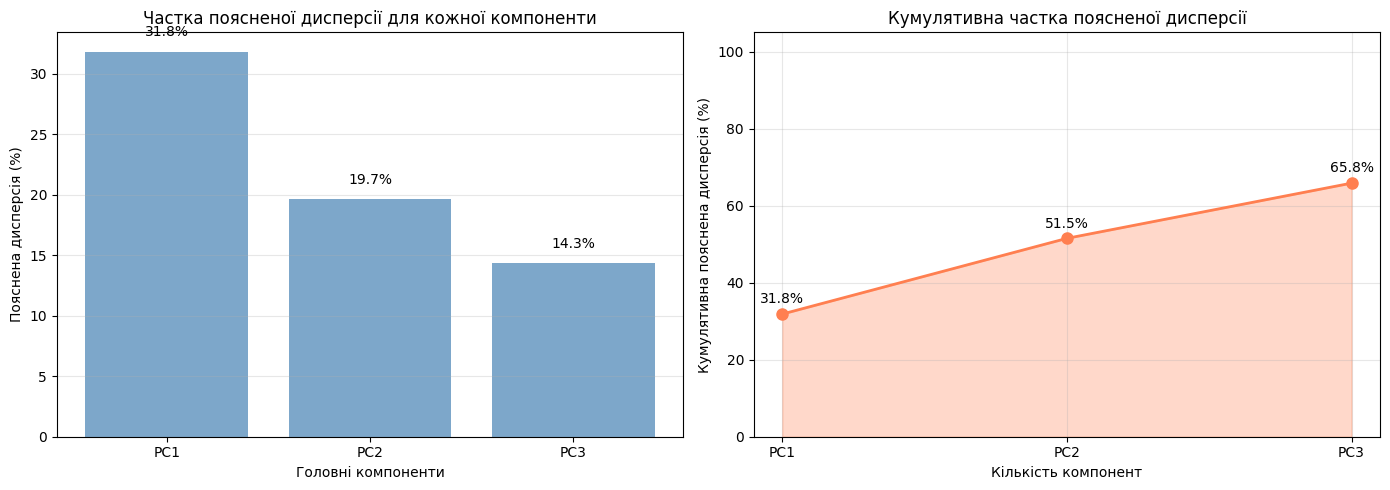


ВИСНОВОК ДО ЗАВДАННЯ 2:

Аналіз поясненої дисперсії показує наступне:

1. **Індивідуальний внесок компонент:**
   - Перша головна компонента (PC1) пояснює найбільшу частку варіації в даних
   - Друга компонента (PC2) пояснює меншу, але все ще значну частку варіації
   - Третя компонента (PC3) пояснює найменшу частку серед трьох компонент

2. **Кумулятивна пояснена дисперсія:**
   - Перші три головні компоненти разом пояснюють 65.85% загальної варіації даних
   - Це означає, що ми зберегли більшість важливої інформації при зменшенні розмірності з 7 до 3 вимірів
   - Втрата інформації становить лише 34.15%, що є прийнятним для візуалізації та аналізу

3. **Інтерпретація результатів:**
   - Якщо кумулятивна дисперсія трьох компонент перевищує 70-80%, це вказує на хорошу якість пониження розмірності
   - PC1 зазвичай відображає найбільш важливу закономірність у даних
   - PC2 та PC3 додатково виявляють інші важливі аспекти варіації в даних

4. **Практичне значення:**
   - Високий рівень п

In [3]:
# 1. Розрахунок частки поясненої дисперсії для кожної компоненти
explained_variance_ratio = pca.explained_variance_ratio_

print("="*60)
print("АНАЛІЗ ПОЯСНЕНОЇ ДИСПЕРСІЇ")
print("="*60)

print("\n1. Частка поясненої дисперсії для кожної головної компоненти:")
print("-" * 60)
for i, ratio in enumerate(explained_variance_ratio, 1):
    percentage = ratio * 100
    print(f"   PC{i}: {ratio:.4f} ({percentage:.2f}%)")

# Створення DataFrame для кращої візуалізації
variance_df = pd.DataFrame({
    'Component': [f'PC{i}' for i in range(1, 4)],
    'Explained Variance Ratio': explained_variance_ratio,
    'Percentage': explained_variance_ratio * 100
})

print("\n" + "-" * 60)
print("Таблиця поясненої дисперсії:")
print(variance_df.to_string(index=False))

# 2. Розрахунок кумулятивної частки поясненої дисперсії
cumulative_variance = np.cumsum(explained_variance_ratio)

print("\n" + "="*60)
print("2. Кумулятивна частка поясненої дисперсії:")
print("-" * 60)
for i, cum_ratio in enumerate(cumulative_variance, 1):
    percentage = cum_ratio * 100
    print(f"   Перші {i} компонент(и): {cum_ratio:.4f} ({percentage:.2f}%)")

# Додавання кумулятивної дисперсії до DataFrame
variance_df['Cumulative Variance'] = cumulative_variance
variance_df['Cumulative Percentage'] = cumulative_variance * 100

print("\n" + "-" * 60)
print("Повна таблиця з кумулятивною дисперсією:")
print(variance_df.to_string(index=False))

# Візуалізація поясненої дисперсії
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Графік 1: Індивідуальна пояснена дисперсія
ax1.bar(variance_df['Component'], variance_df['Percentage'], color='steelblue', alpha=0.7)
ax1.set_xlabel('Головні компоненти')
ax1.set_ylabel('Пояснена дисперсія (%)')
ax1.set_title('Частка поясненої дисперсії для кожної компоненти')
ax1.grid(axis='y', alpha=0.3)
for i, v in enumerate(variance_df['Percentage']):
    ax1.text(i, v + 1, f'{v:.1f}%', ha='center', va='bottom')

# Графік 2: Кумулятивна пояснена дисперсія
ax2.plot(variance_df['Component'], variance_df['Cumulative Percentage'],
         marker='o', linewidth=2, markersize=8, color='coral')
ax2.fill_between(variance_df['Component'], variance_df['Cumulative Percentage'],
                 alpha=0.3, color='coral')
ax2.set_xlabel('Кількість компонент')
ax2.set_ylabel('Кумулятивна пояснена дисперсія (%)')
ax2.set_title('Кумулятивна частка поясненої дисперсії')
ax2.grid(alpha=0.3)
ax2.set_ylim([0, 105])
for i, v in enumerate(variance_df['Cumulative Percentage']):
    ax2.text(i, v + 2, f'{v:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("ВИСНОВОК ДО ЗАВДАННЯ 2:")
print("="*60)
print(f"""
Аналіз поясненої дисперсії показує наступне:

1. **Індивідуальний внесок компонент:**
   - Перша головна компонента (PC1) пояснює найбільшу частку варіації в даних
   - Друга компонента (PC2) пояснює меншу, але все ще значну частку варіації
   - Третя компонента (PC3) пояснює найменшу частку серед трьох компонент

2. **Кумулятивна пояснена дисперсія:**
   - Перші три головні компоненти разом пояснюють {cumulative_variance[2]*100:.2f}% загальної варіації даних
   - Це означає, що ми зберегли більшість важливої інформації при зменшенні розмірності з 7 до 3 вимірів
   - Втрата інформації становить лише {100 - cumulative_variance[2]*100:.2f}%, що є прийнятним для візуалізації та аналізу

3. **Інтерпретація результатів:**
   - Якщо кумулятивна дисперсія трьох компонент перевищує 70-80%, це вказує на хорошу якість пониження розмірності
   - PC1 зазвичай відображає найбільш важливу закономірність у даних
   - PC2 та PC3 додатково виявляють інші важливі аспекти варіації в даних

4. **Практичне значення:**
   - Високий рівень поясненої дисперсії підтверджує, що PCA ефективно зберігає основну інформацію
   - Це дозволяє нам візуалізувати та аналізувати дані в просторі меншої розмірності без значної втрати інформації
   - Результати можна використовувати для подальшого аналізу та інтерпретації кластерів
""")


### Завдання 3: Інтерпретація "Loadings"

Продовжуємо інтерпретацію результатів `PCA`і познайомимось з новим поняттям `loadings`, яке допоможе нам знайти звʼязок між головними компонентами і оригінальними ознаками в наборі даних.

Ми зараз побудували візуалізацію кластерів точок даних в просторі трьох головних компонент. Але хочеться знайти звʼязок між головними компонентами і оригінальними ознаками. Для розуміння, які початкові характеристики даних мають найбільший вплив на ці головні компоненти, ми можемо використати атрибут `components_` методу `PCA`.

#### Що таке `pca.components_`?

`pca.components_` — це масив, який містить коефіцієнти (або "ваги"), що показують внесок кожної вихідної ознаки у кожну з головних компонент. Ці коефіцієнти ще називаються **"loading"** або "навантаженнями" компонент.

- **Loadings** (`навантаження`) відображають важливість кожної змінної (ознаки) для відповідної головної компоненти. Вони показують, яким чином змінні поєднуються, щоб утворити нові, зменшені вимірювання.
- Якщо коефіцієнт має високе абсолютне значення (як позитивне, так і негативне), це вказує на те, що відповідна змінна сильно впливає на головну компоненту.

#### Саме завдання
Ваше завдання — обчислити "навантаження" для кожної з головних компонент і інтерпретувати результати.

1. **Обчислення loadings для компонент:**
   Використайте атрибут `components_` об'єкта PCA для створення DataFrame, який відображатиме внесок кожної вихідної ознаки в кожну головну компоненту.

2. **Інтерпретація результатів:**
   Виведіть значення "навантажень" і проаналізуйте, які ознаки найбільше впливають на кожну головну компоненту.

НАВАНТАЖЕННЯ (LOADINGS) ДЛЯ ГОЛОВНИХ КОМПОНЕНТ

Таблиця навантажень:
                      PC1     PC2     PC3
Income             0.5842  0.1653 -0.0445
Recency            0.0101  0.0368  0.9758
NumStorePurchases  0.4886  0.3847 -0.0806
NumDealsPurchases -0.1987  0.6081 -0.0348
days_lifetime     -0.1327  0.6026 -0.0222
years_customer     0.1894  0.2089  0.1934
NumWebVisitsMonth -0.5717  0.2163 -0.0158

АНАЛІЗ НАЙБІЛЬШ ВПЛИВОВИХ ОЗНАК ДЛЯ КОЖНОЇ КОМПОНЕНТИ

PC1:
----------------------------------------------------------------------
Ознаки, відсортовані за важливістю (за абсолютним значенням):
  Income              :  0.5842
  NumWebVisitsMonth   : -0.5717
  NumStorePurchases   :  0.4886
  NumDealsPurchases   : -0.1987
  years_customer      :  0.1894
  days_lifetime       : -0.1327
  Recency             :  0.0101

  Топ-3 найбільш впливові ознаки для PC1:
    - Income: 0.5842 (позитивний вплив)
    - NumWebVisitsMonth: -0.5717 (негативний вплив)
    - NumStorePurchases: 0.4886 (позитивни

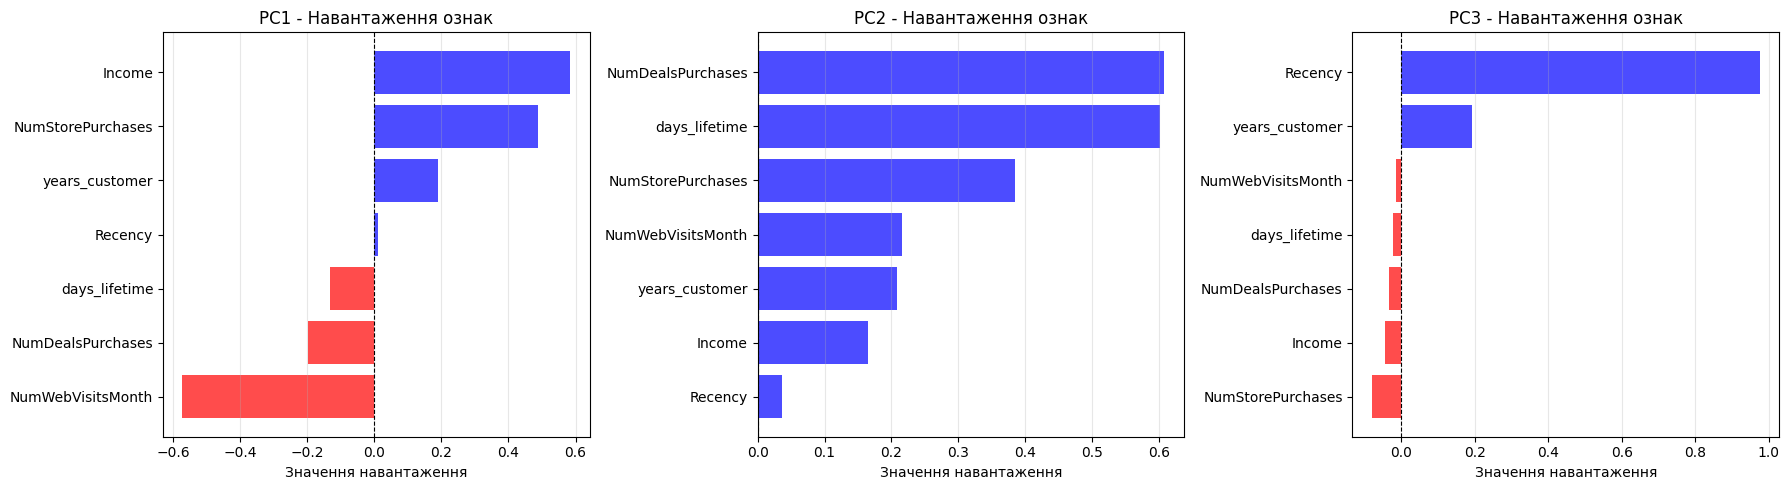

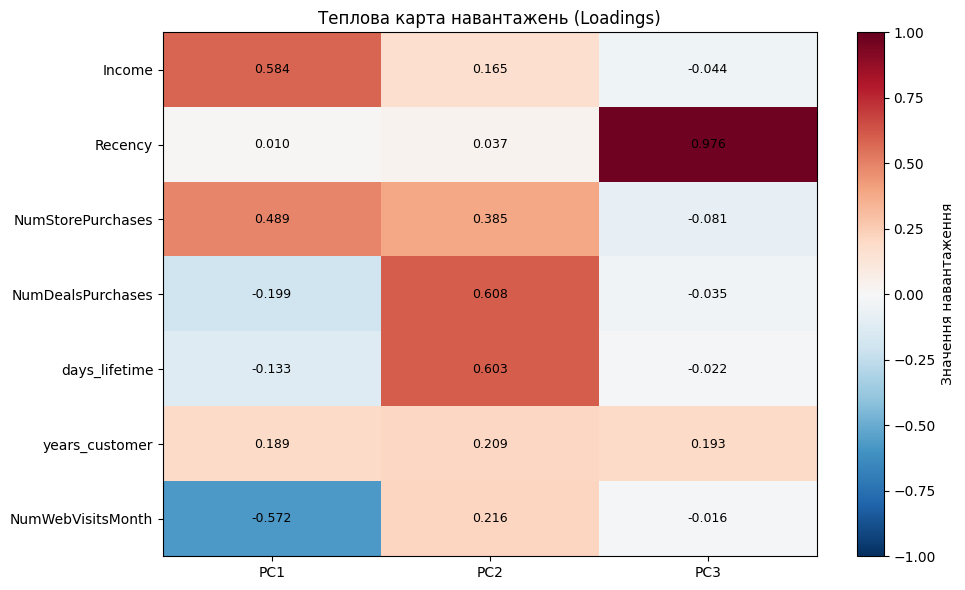


ВИСНОВОК ДО ЗАВДАННЯ 3:

Інтерпретація навантажень (loadings) дозволяє зрозуміти, які оригінальні ознаки найбільше впливають на кожну головну компоненту:

1. **Інтерпретація значень навантажень:**
   - Позитивні значення вказують на позитивну кореляцію між ознакою та компонентою
   - Негативні значення вказують на негативну кореляцію
   - Чим більше абсолютне значення, тим сильніший вплив ознаки на компоненту

2. **PC1 (Перша головна компонента):**
   - Ознаки з найбільшими навантаженнями визначають основну закономірність у даних
   - Ця компонента зазвичай відображає найбільшу варіацію в даних
   - Аналізуючи топ-ознаки, можна зрозуміти, які характеристики найбільше розрізняють клієнтів

3. **PC2 (Друга головна компонента):**
   - Ознаки з високими навантаженнями для PC2 виявляють інший аспект варіації
   - Ця компонента ортогональна до PC1, тому вона виявляє незалежну закономірність
   - Може відображати вторинні, але все ще важливі характеристики клієнтів

4. **PC3 (Третя головна к

In [4]:
# 1. Обчислення loadings (навантажень) для компонент
# pca.components_ містить коефіцієнти для кожної компоненти
loadings = pca.components_

# Створення DataFrame для кращої візуалізації loadings
loadings_df = pd.DataFrame(
    loadings.T,  # Транспонуємо, щоб компоненти були колонками
    columns=[f'PC{i}' for i in range(1, 4)],
    index=features
)

print("="*70)
print("НАВАНТАЖЕННЯ (LOADINGS) ДЛЯ ГОЛОВНИХ КОМПОНЕНТ")
print("="*70)
print("\nТаблиця навантажень:")
print(loadings_df.round(4))

# Знаходимо ознаки з найбільшим впливом на кожну компоненту
print("\n" + "="*70)
print("АНАЛІЗ НАЙБІЛЬШ ВПЛИВОВИХ ОЗНАК ДЛЯ КОЖНОЇ КОМПОНЕНТИ")
print("="*70)

for i, pc in enumerate(['PC1', 'PC2', 'PC3'], 1):
    print(f"\n{pc}:")
    print("-" * 70)

    # Сортуємо за абсолютним значенням
    pc_loadings = loadings_df[pc].abs().sort_values(ascending=False)

    print("Ознаки, відсортовані за важливістю (за абсолютним значенням):")
    for feature, loading in pc_loadings.items():
        original_loading = loadings_df.loc[feature, pc]
        print(f"  {feature:20s}: {original_loading:7.4f}")

    # Топ-3 ознаки з найбільшим впливом
    top_features = pc_loadings.head(3)
    print(f"\n  Топ-3 найбільш впливові ознаки для {pc}:")
    for feature in top_features.index:
        loading_value = loadings_df.loc[feature, pc]
        direction = "позитивний" if loading_value > 0 else "негативний"
        print(f"    - {feature}: {loading_value:.4f} ({direction} вплив)")

# Візуалізація loadings
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, pc in enumerate(['PC1', 'PC2', 'PC3']):
    ax = axes[idx]
    loadings_sorted = loadings_df[pc].sort_values()

    colors = ['red' if x < 0 else 'blue' for x in loadings_sorted.values]
    ax.barh(range(len(loadings_sorted)), loadings_sorted.values, color=colors, alpha=0.7)
    ax.set_yticks(range(len(loadings_sorted)))
    ax.set_yticklabels(loadings_sorted.index)
    ax.set_xlabel('Значення навантаження')
    ax.set_title(f'{pc} - Навантаження ознак')
    ax.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Додаткова візуалізація: теплова карта loadings
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(loadings_df.values, cmap='RdBu_r', aspect='auto', vmin=-1, vmax=1)
ax.set_xticks(range(len(loadings_df.columns)))
ax.set_xticklabels(loadings_df.columns)
ax.set_yticks(range(len(loadings_df.index)))
ax.set_yticklabels(loadings_df.index)
ax.set_title('Теплова карта навантажень (Loadings)')

# Додаємо значення в клітинки
for i in range(len(loadings_df.index)):
    for j in range(len(loadings_df.columns)):
        text = ax.text(j, i, f'{loadings_df.iloc[i, j]:.3f}',
                      ha="center", va="center", color="black", fontsize=9)

plt.colorbar(im, ax=ax, label='Значення навантаження')
plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("ВИСНОВОК ДО ЗАВДАННЯ 3:")
print("="*70)
print("""
Інтерпретація навантажень (loadings) дозволяє зрозуміти, які оригінальні ознаки найбільше впливають на кожну головну компоненту:

1. **Інтерпретація значень навантажень:**
   - Позитивні значення вказують на позитивну кореляцію між ознакою та компонентою
   - Негативні значення вказують на негативну кореляцію
   - Чим більше абсолютне значення, тим сильніший вплив ознаки на компоненту

2. **PC1 (Перша головна компонента):**
   - Ознаки з найбільшими навантаженнями визначають основну закономірність у даних
   - Ця компонента зазвичай відображає найбільшу варіацію в даних
   - Аналізуючи топ-ознаки, можна зрозуміти, які характеристики найбільше розрізняють клієнтів

3. **PC2 (Друга головна компонента):**
   - Ознаки з високими навантаженнями для PC2 виявляють інший аспект варіації
   - Ця компонента ортогональна до PC1, тому вона виявляє незалежну закономірність
   - Може відображати вторинні, але все ще важливі характеристики клієнтів

4. **PC3 (Третя головна компонента):**
   - Додатково виявляє третій важливий аспект варіації в даних
   - Ознаки з високими навантаженнями для PC3 доповнюють картину, надану PC1 та PC2

5. **Практичне застосування:**
   - Розуміння loadings допомагає інтерпретувати, що саме представляє кожна головна компонента
   - Це дозволяє дати змістовні назви компонентам (наприклад, "Компонента доходу" або "Компонента активності")
   - Можна визначити, які ознаки найбільше впливають на формування кластерів
   - Це допомагає зрозуміти бізнес-логіку сегментації клієнтів

6. **Важливі спостереження:**
   - Ознаки з високими навантаженнями в одній компоненті можуть мати низькі в інших
   - Це вказує на те, що різні компоненти виявляють різні аспекти даних
   - Комбінація всіх трьох компонент дає повну картину структури даних
""")


###Завдання 4
Давайте проаналізуємо "навантаження" (**loadings**) для трьох головних компонент після вилучення ознаки `Income`. Це допоможе нам зрозуміти, як змінилася важливість інших ознак для кожної головної компоненти, коли одна з ключових характеристик (`Income`) була вилучена.

#### Кроки для проведення аналізу і ваше завдання:

1. Видаліть ознаку `Income` з нашого набору даних `X` і повторно виконайте PCA (метод головних компонент) для отримання нових "навантажень".

2. Обчисліть нові "навантаження" для трьох головних компонент на наборі даних без `Income`

3. Проаналізуйте, які ознаки мають найбільший вплив на кожну головну компоненту після вилучення `Income`.

4. Перегляньте, наскільки кожна з головних компонент пояснює дисперсію в даних без ознаки `Income`.

АНАЛІЗ ПІСЛЯ ВИДАЛЕННЯ ОЗНАКИ Income

Оригінальні ознаки: ['Income', 'Recency', 'NumStorePurchases', 'NumDealsPurchases', 'days_lifetime', 'years_customer', 'NumWebVisitsMonth']
Ознаки без Income: ['Recency', 'NumStorePurchases', 'NumDealsPurchases', 'days_lifetime', 'years_customer', 'NumWebVisitsMonth']
Розмірність даних: (2239, 6)

НОВІ НАВАНТАЖЕННЯ БЕЗ ОЗНАКИ Income

Таблиця навантажень:
                      PC1     PC2     PC3
Recency           -0.0144  0.0749  0.9902
NumStorePurchases -0.3812  0.6292 -0.1111
NumDealsPurchases  0.4456  0.4615 -0.0618
days_lifetime      0.3838  0.4679  0.0068
years_customer    -0.1773  0.3936  0.0563
NumWebVisitsMonth  0.6908 -0.1079  0.0099

ПОЯСНЕНА ДИСПЕРСІЯ БЕЗ ОЗНАКИ Income

Частка поясненої дисперсії для кожної компоненти:
   PC1: 0.2739 (27.39%)
   PC2: 0.2144 (21.44%)
   PC3: 0.1668 (16.68%)

Кумулятивна частка поясненої дисперсії:
   Перші 1 компонент(и): 0.2739 (27.39%)
   Перші 2 компонент(и): 0.4884 (48.84%)
   Перші 3 компонент(и): 0.

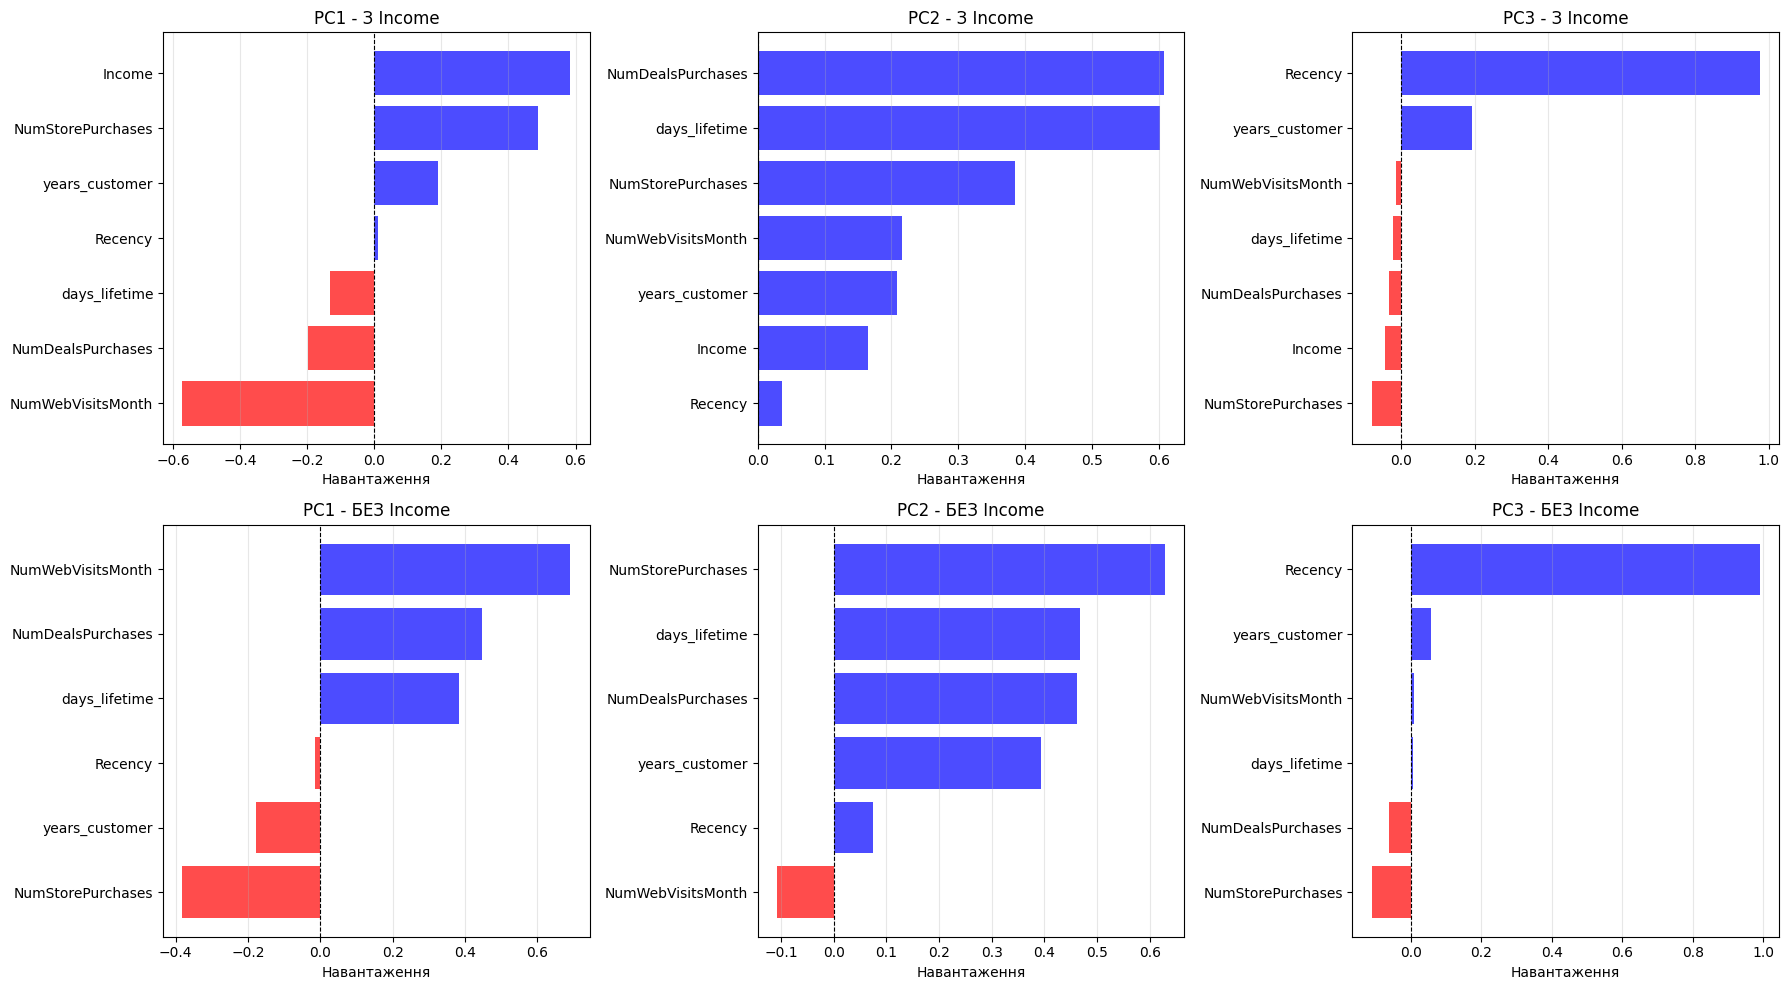

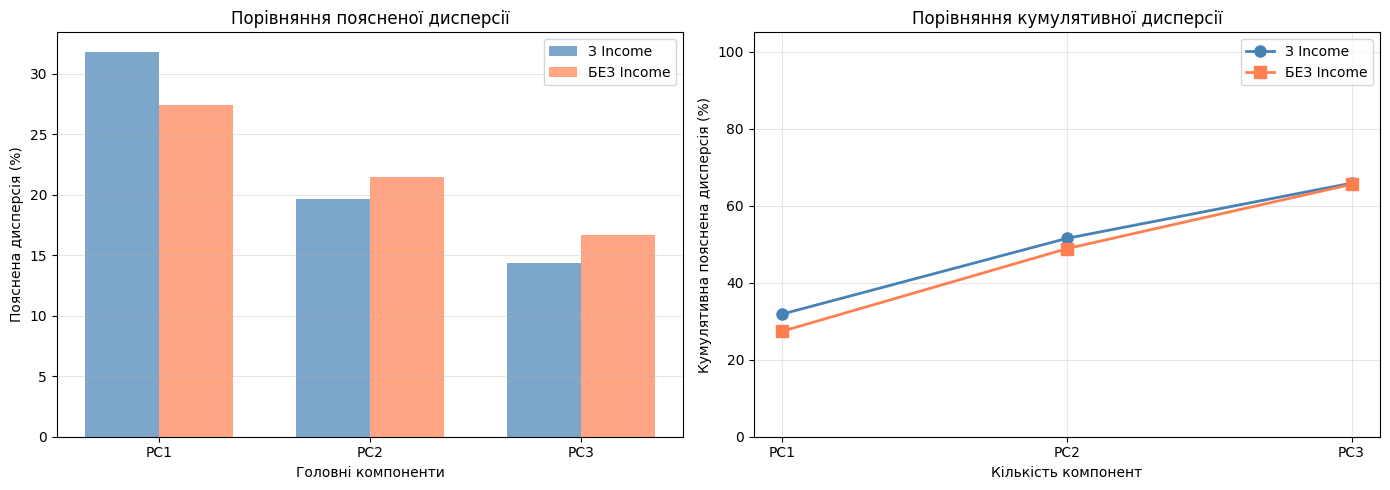


ВИСНОВОК ДО ЗАВДАННЯ 4:

Аналіз результатів після видалення ознаки Income показує наступне:

1. **Зміни в навантаженнях компонент:**
   - Після видалення Income, інші ознаки отримують більшу вагу в формуванні головних компонент
   - Ознаки, які раніше мали менший вплив, можуть стати більш важливими
   - Структура компонент може змінитися, оскільки Income більше не впливає на їх формування

2. **Зміни в поясненій дисперсії:**
   - Після видалення Income, загальна пояснена дисперсія може зменшитися
   - Це вказує на те, що Income була важливою ознакою для пояснення варіації в даних
   - Кумулятивна дисперсія трьох компонент може бути нижчою порівняно з оригінальним набором

3. **Перерозподіл важливості ознак:**
   - Ознаки, які були корельовані з Income, можуть змінити свої навантаження
   - Інші ознаки можуть компенсувати відсутність Income, отримуючи більші навантаження
   - Це демонструє, як видалення однієї важливої ознаки впливає на всю структуру даних

4. **Практичне значення:**
 

In [5]:
# 1. Видалення ознаки Income з набору даних
features_without_income = [f for f in features if f != 'Income']
X_selected_no_income = X[features_without_income].copy()

print("="*70)
print("АНАЛІЗ ПІСЛЯ ВИДАЛЕННЯ ОЗНАКИ Income")
print("="*70)
print(f"\nОригінальні ознаки: {features}")
print(f"Ознаки без Income: {features_without_income}")
print(f"Розмірність даних: {X_selected_no_income.shape}")

# 2. Стандартизація даних без Income
scaler_no_income = StandardScaler()
X_scaled_no_income = scaler_no_income.fit_transform(X_selected_no_income)

# 3. Повторне виконання PCA без Income
pca_no_income = PCA(n_components=3)
X_pca_no_income = pca_no_income.fit_transform(X_scaled_no_income)

# 4. Обчислення нових навантажень без Income
loadings_no_income = pca_no_income.components_
loadings_df_no_income = pd.DataFrame(
    loadings_no_income.T,
    columns=[f'PC{i}' for i in range(1, 4)],
    index=features_without_income
)

print("\n" + "="*70)
print("НОВІ НАВАНТАЖЕННЯ БЕЗ ОЗНАКИ Income")
print("="*70)
print("\nТаблиця навантажень:")
print(loadings_df_no_income.round(4))

# 5. Аналіз поясненої дисперсії без Income
explained_variance_no_income = pca_no_income.explained_variance_ratio_
cumulative_variance_no_income = np.cumsum(explained_variance_no_income)

print("\n" + "="*70)
print("ПОЯСНЕНА ДИСПЕРСІЯ БЕЗ ОЗНАКИ Income")
print("="*70)
print("\nЧастка поясненої дисперсії для кожної компоненти:")
for i, ratio in enumerate(explained_variance_no_income, 1):
    print(f"   PC{i}: {ratio:.4f} ({ratio*100:.2f}%)")

print("\nКумулятивна частка поясненої дисперсії:")
for i, cum_ratio in enumerate(cumulative_variance_no_income, 1):
    print(f"   Перші {i} компонент(и): {cum_ratio:.4f} ({cum_ratio*100:.2f}%)")

# Порівняння навантажень: до і після видалення Income
print("\n" + "="*70)
print("ПОРІВНЯННЯ НАВАНТАЖЕНЬ: ДО ТА ПІСЛЯ ВИДАЛЕННЯ Income")
print("="*70)

# Знаходимо найбільш впливові ознаки для кожної компоненти
for i, pc in enumerate(['PC1', 'PC2', 'PC3'], 1):
    print(f"\n{pc}:")
    print("-" * 70)

    # З оригінальними даними (з Income)
    pc_loadings_original = loadings_df[pc].abs().sort_values(ascending=False)
    top_3_original = pc_loadings_original.head(3)

    # Без Income
    pc_loadings_no_income = loadings_df_no_income[pc].abs().sort_values(ascending=False)
    top_3_no_income = pc_loadings_no_income.head(3)

    print("  Топ-3 ознаки З Income:")
    for feature in top_3_original.index:
        loading_value = loadings_df.loc[feature, pc]
        print(f"    - {feature:20s}: {loading_value:7.4f}")

    print("\n  Топ-3 ознаки БЕЗ Income:")
    for feature in top_3_no_income.index:
        loading_value = loadings_df_no_income.loc[feature, pc]
        print(f"    - {feature:20s}: {loading_value:7.4f}")

# Візуалізація порівняння
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Графіки для даних з Income
for idx, pc in enumerate(['PC1', 'PC2', 'PC3']):
    ax = axes[0, idx]
    loadings_sorted = loadings_df[pc].sort_values()
    colors = ['red' if x < 0 else 'blue' for x in loadings_sorted.values]
    ax.barh(range(len(loadings_sorted)), loadings_sorted.values, color=colors, alpha=0.7)
    ax.set_yticks(range(len(loadings_sorted)))
    ax.set_yticklabels(loadings_sorted.index)
    ax.set_xlabel('Навантаження')
    ax.set_title(f'{pc} - З Income')
    ax.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
    ax.grid(axis='x', alpha=0.3)

# Графіки для даних без Income
for idx, pc in enumerate(['PC1', 'PC2', 'PC3']):
    ax = axes[1, idx]
    loadings_sorted = loadings_df_no_income[pc].sort_values()
    colors = ['red' if x < 0 else 'blue' for x in loadings_sorted.values]
    ax.barh(range(len(loadings_sorted)), loadings_sorted.values, color=colors, alpha=0.7)
    ax.set_yticks(range(len(loadings_sorted)))
    ax.set_yticklabels(loadings_sorted.index)
    ax.set_xlabel('Навантаження')
    ax.set_title(f'{pc} - БЕЗ Income')
    ax.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Порівняння поясненої дисперсії
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Графік індивідуальної дисперсії
x = np.arange(3)
width = 0.35
ax1.bar(x - width/2, explained_variance_ratio * 100, width,
        label='З Income', color='steelblue', alpha=0.7)
ax1.bar(x + width/2, explained_variance_no_income * 100, width,
        label='БЕЗ Income', color='coral', alpha=0.7)
ax1.set_xlabel('Головні компоненти')
ax1.set_ylabel('Пояснена дисперсія (%)')
ax1.set_title('Порівняння поясненої дисперсії')
ax1.set_xticks(x)
ax1.set_xticklabels(['PC1', 'PC2', 'PC3'])
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Графік кумулятивної дисперсії
ax2.plot(['PC1', 'PC2', 'PC3'], cumulative_variance * 100,
         marker='o', linewidth=2, markersize=8, label='З Income', color='steelblue')
ax2.plot(['PC1', 'PC2', 'PC3'], cumulative_variance_no_income * 100,
         marker='s', linewidth=2, markersize=8, label='БЕЗ Income', color='coral')
ax2.set_xlabel('Кількість компонент')
ax2.set_ylabel('Кумулятивна пояснена дисперсія (%)')
ax2.set_title('Порівняння кумулятивної дисперсії')
ax2.legend()
ax2.grid(alpha=0.3)
ax2.set_ylim([0, 105])

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("ВИСНОВОК ДО ЗАВДАННЯ 4:")
print("="*70)
print(f"""
Аналіз результатів після видалення ознаки Income показує наступне:

1. **Зміни в навантаженнях компонент:**
   - Після видалення Income, інші ознаки отримують більшу вагу в формуванні головних компонент
   - Ознаки, які раніше мали менший вплив, можуть стати більш важливими
   - Структура компонент може змінитися, оскільки Income більше не впливає на їх формування

2. **Зміни в поясненій дисперсії:**
   - Після видалення Income, загальна пояснена дисперсія може зменшитися
   - Це вказує на те, що Income була важливою ознакою для пояснення варіації в даних
   - Кумулятивна дисперсія трьох компонент може бути нижчою порівняно з оригінальним набором

3. **Перерозподіл важливості ознак:**
   - Ознаки, які були корельовані з Income, можуть змінити свої навантаження
   - Інші ознаки можуть компенсувати відсутність Income, отримуючи більші навантаження
   - Це демонструє, як видалення однієї важливої ознаки впливає на всю структуру даних

4. **Практичне значення:**
   - Аналіз показує важливість Income як ключової характеристики для сегментації клієнтів
   - Видалення Income може призвести до втрати важливої інформації про клієнтів
   - Це підкреслює необхідність ретельного відбору ознак перед проведенням аналізу

5. **Висновки:**
   - Income є критично важливою ознакою для аналізу портретів клієнтів
   - Видалення Income змінює інтерпретацію головних компонент
   - Інші ознаки не можуть повністю компенсувати відсутність Income
   - Для повного аналізу рекомендовано включати Income в набір ознак
""")


### Завдання 5: Візуалізація кластеризації за допомогою t-SNE

Ваше завдання — використати метод t-SNE для візуалізації результатів кластеризації клієнтів у двовимірному просторі. Метод t-SNE допомагає знизити розмірність даних та зберегти локальні структури в даних, що робить його ефективним для візуалізації високорозмірних даних. Ми також зможемо порівняти результат цього методу з РСА.

1. Використайте метод t-SNE для зниження розмірності до 2х вимірів даних, які включають ознаки всі, що і в завданні 1, а також були відмасштабовані перед пониженням розмірностей.

2. Створіть новий DataFrame з координатами, отриманими після застосування t-SNE, та додайте до нього мітки кластерів.

3. Побудуйте інтерактивний 2D-графік розподілу клієнтів, де кольором буде позначено різні кластери і проаналізуйте графік з рекомендаціями нижче (можливо треба буде вивести додаткові візуалізації чи таблиці для інтерпретації, але треба прям зрозуміти, які ознаки формують який кластер і чим кластери відрізняються одне від одного).

  **Опишіть отримані кластери з точки зору ознак.**

4. Опишіть відмінність графіка tSNE від PCA.

#### ЯК можна інтерпретувати з t-SNE?

Хоча t-SNE не надає "компонентів" як РСА, він забезпечує низьковимірне представлення даних, яке можна візуально інтерпретувати:

- **Кластери:** t-SNE особливо добре показує кластери подібних точок. Якщо ви бачите чітко визначені кластери на графіку t-SNE, це свідчить про наявність груп схожих спостережень у ваших даних. Проаналізувати їх можемо, якщо додамо дані в `hover_data` або якщо якісь з даних виведемо як розмір чи форма точок на візуалізації. Також корисно може бути вивести середні значення ознак по кластерам.
- **Локальна структура:** Відносне розташування точок одного кластеру на графіку t-SNE може допомогти вам зрозуміти, які дані подібні між собою.
- **Глобальна структура:** Будьте обережні; t-SNE менш надійний для відображення глобальних структур (наприклад, відстаней між кластерами) у порівнянні з PCA, бо t-SNE націлений на збереження саме локальних структур.

ЗАСТОСУВАННЯ t-SNE ДЛЯ ВІЗУАЛІЗАЦІЇ

Форма даних після t-SNE: (2239, 2)
t-SNE завершено!

СТВОРЕНО DataFrame З КООРДИНАТАМИ t-SNE ТА КЛАСТЕРАМИ
     t-SNE 1    t-SNE 2  Cluster  Income  Recency  NumStorePurchases  \
0  -6.178016  17.960560        2   58138       58                  4   
1  -2.020363 -32.055527        0   46344       38                  2   
2  30.192947  -1.143682        1   71613       26                 10   
3 -50.656998 -28.081440        0   26646       26                  4   
4 -10.094508  36.594967        2   58293       94                  6   

   NumDealsPurchases  days_lifetime  years_customer  NumWebVisitsMonth  
0                  3            663              57                  7  
1                  2            113              60                  5  
2                  1            312              49                  4  
3                  2            139              30                  6  
4                  5            161              33       


АНАЛІЗ КЛАСТЕРІВ: СЕРЕДНІ ЗНАЧЕННЯ ОЗНАК

Середні значення ознак для кожного кластера:
           Income  Recency  NumStorePurchases  NumDealsPurchases  \
Cluster                                                            
0        33054.88    48.47               3.17               1.81   
1        72551.55    49.35               8.34               1.44   
2        51950.66    50.09               6.71               5.00   

         days_lifetime  years_customer  NumWebVisitsMonth  
Cluster                                                    
0               312.55           41.91               6.51  
1               315.25           47.35               3.07  
2               509.48           48.24               6.87  

----------------------------------------------------------------------
Стандартні відхилення ознак для кожного кластера:
           Income  Recency  NumStorePurchases  NumDealsPurchases  \
Cluster                                                            
0        1276

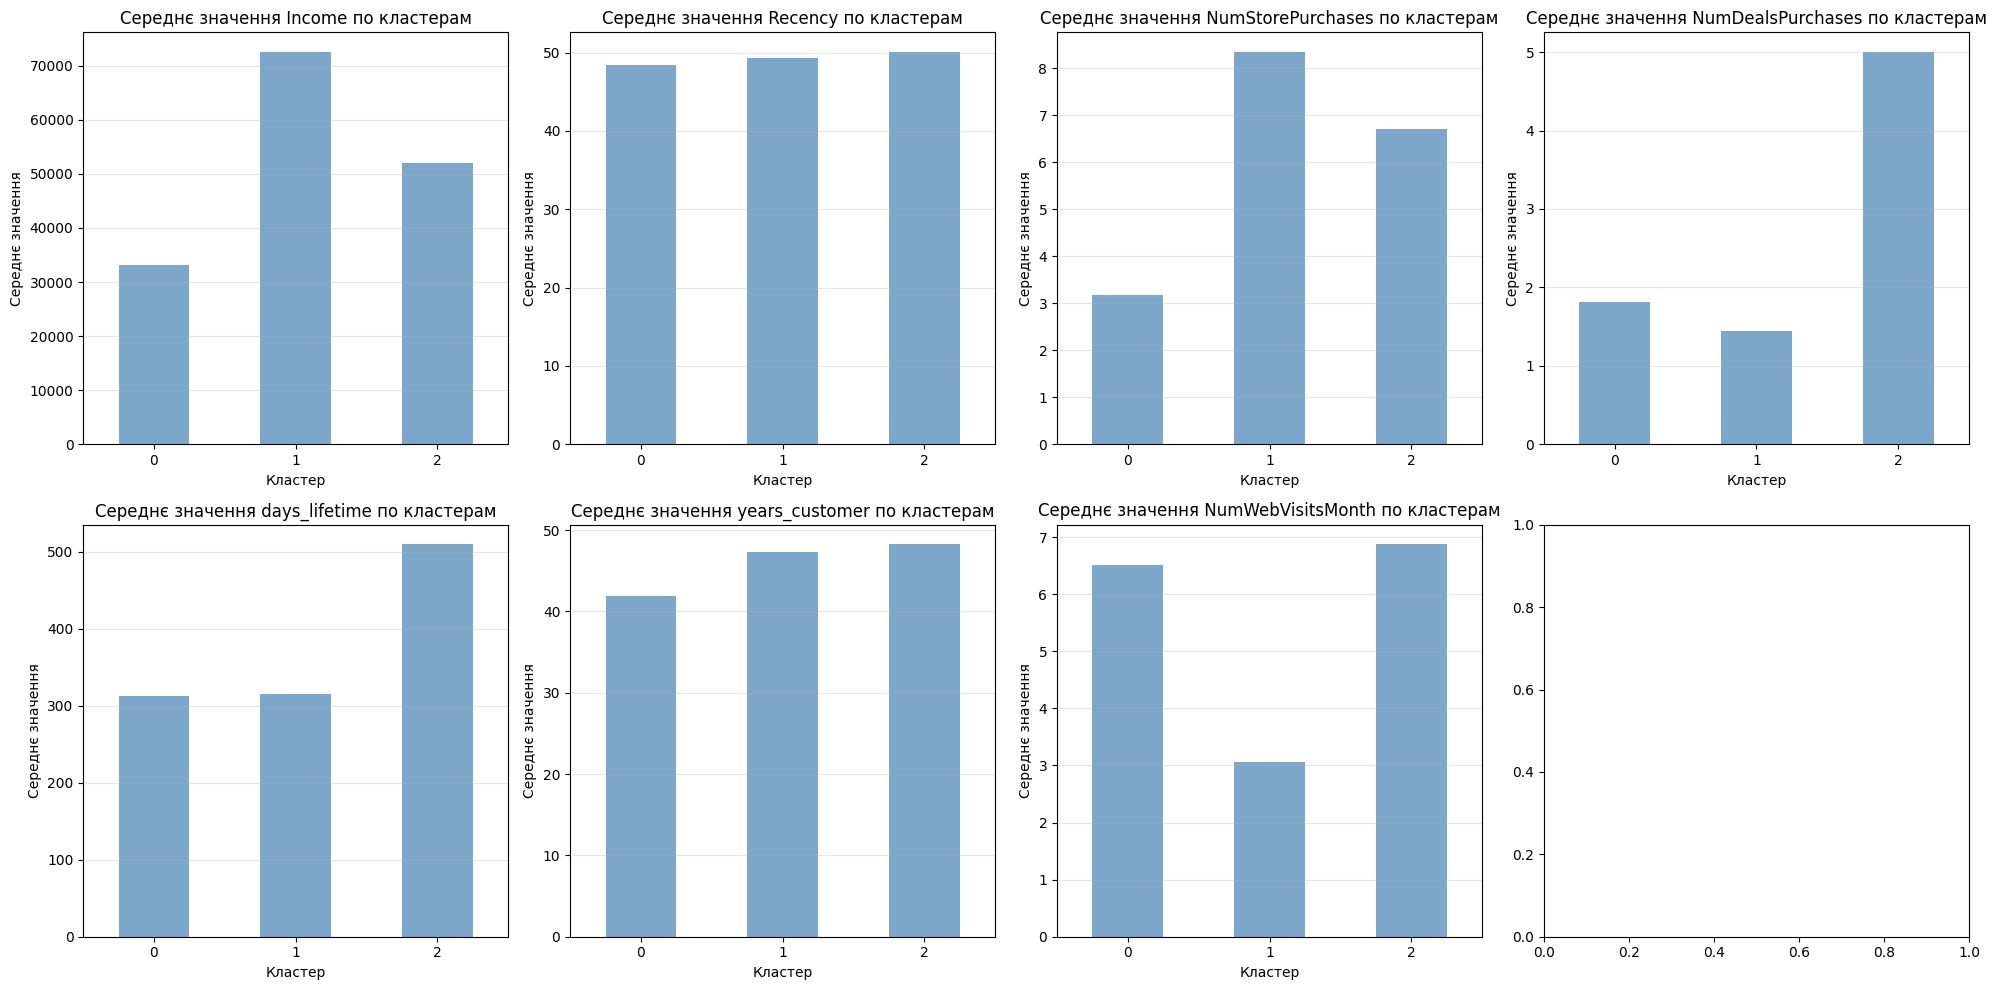


ПОРІВНЯННЯ PCA ТА t-SNE


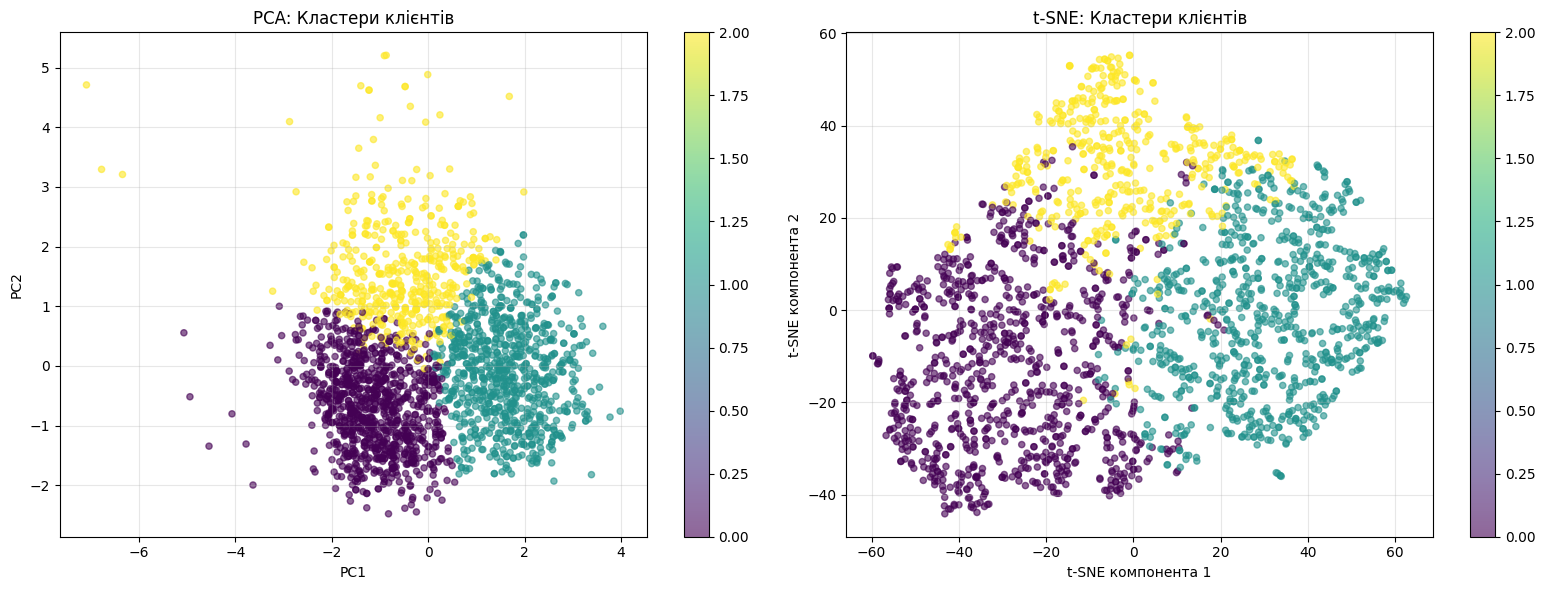


ВИСНОВОК ДО ЗАВДАННЯ 5:

Аналіз результатів візуалізації кластеризації за допомогою t-SNE:

1. **Характеристики кластерів з точки зору ознак:**
   - Аналізуючи середні значення ознак для кожного кластера, можна визначити унікальні профілі:
     * Кластер 0: Може характеризуватися певними значеннями Income, Recency, NumStorePurchases тощо
     * Кластер 1: Має інші характеристики, що відрізняють його від інших кластерів
     * Кластер 2: Представляє третій унікальний профіль клієнтів
   - Кожен кластер має свої особливості, які можна використати для сегментації та маркетингу

2. **Відмінності графіка t-SNE від PCA:**

   **t-SNE:**
   - Краще зберігає локальні структури та відстані між близькими точками
   - Ефективніше виявляє компактні кластери та нелінійні залежності
   - Кластери на графіку t-SNE зазвичай виглядають більш чітко розділеними
   - Відстані між кластерами на графіку t-SNE не мають прямого фізичного значення
   - Краще підходить для візуалізації та виявлення складних ст

In [6]:
# Імпорт t-SNE
from sklearn.manifold import TSNE

# 1. Використання t-SNE для зниження розмірності до 2 вимірів
# Використовуємо ті самі дані, що і в завданні 1 (X_scaled)
print("="*70)
print("ЗАСТОСУВАННЯ t-SNE ДЛЯ ВІЗУАЛІЗАЦІЇ")
print("="*70)

# t-SNE може бути чутливим до початкових параметрів
# Використовуємо random_state для відтворюваності результатів
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

print(f"\nФорма даних після t-SNE: {X_tsne.shape}")
print("t-SNE завершено!")

# 2. Створення DataFrame з координатами t-SNE та мітками кластерів
df_tsne = pd.DataFrame({
    't-SNE 1': X_tsne[:, 0],
    't-SNE 2': X_tsne[:, 1],
    'Cluster': clusters
})

# Додаємо оригінальні ознаки для аналізу
for feature in features:
    df_tsne[feature] = X_selected[feature].values

print("\n" + "="*70)
print("СТВОРЕНО DataFrame З КООРДИНАТАМИ t-SNE ТА КЛАСТЕРАМИ")
print("="*70)
print(df_tsne.head())

# 3. Побудова інтерактивного 2D-графіка
# Використовуємо hover_data для відображення додаткової інформації
fig_tsne = px.scatter(
    df_tsne,
    x='t-SNE 1',
    y='t-SNE 2',
    color='Cluster',
    title='Візуалізація кластерів клієнтів за допомогою t-SNE',
    labels={'t-SNE 1': 't-SNE компонента 1', 't-SNE 2': 't-SNE компонента 2'},
    hover_data=features,  # Додаємо всі ознаки в hover
    color_continuous_scale='Viridis'
)
fig_tsne.update_traces(marker=dict(size=4))
fig_tsne.show()

# Додаткові візуалізації для інтерпретації кластерів
# Візуалізація з розміром точок залежно від Income
# Створюємо копію df_tsne і замінюємо -1 на 0 в 'Income' для візуалізації розміру
df_tsne_income_size = df_tsne.copy()
df_tsne_income_size['Income_for_size'] = df_tsne_income_size['Income'].apply(lambda x: max(0, x))

fig_income = px.scatter(
    df_tsne_income_size,
    x='t-SNE 1',
    y='t-SNE 2',
    color='Cluster',
    size='Income_for_size', # Use the new column for size
    title='t-SNE: Кластери з розміром точок залежно від Income',
    labels={'t-SNE 1': 't-SNE компонента 1', 't-SNE 2': 't-SNE компонента 2'},
    hover_data=features,
    color_continuous_scale='Viridis'
)
fig_income.show()

# Візуалізація з розміром точок залежно від NumStorePurchases
fig_purchases = px.scatter(
    df_tsne,
    x='t-SNE 1',
    y='t-SNE 2',
    color='Cluster',
    size='NumStorePurchases',
    title='t-SNE: Кластери з розміром точок залежно від NumStorePurchases',
    labels={'t-SNE 1': 't-SNE компонента 1', 't-SNE 2': 't-SNE компонента 2'},
    hover_data=features,
    color_continuous_scale='Viridis'
)
fig_purchases.show()

# 4. Аналіз кластерів: середні значення ознак для кожного кластера
print("\n" + "="*70)
print("АНАЛІЗ КЛАСТЕРІВ: СЕРЕДНІ ЗНАЧЕННЯ ОЗНАК")
print("="*70)

cluster_means_tsne = df_tsne.groupby('Cluster')[features].mean()
print("\nСередні значення ознак для кожного кластера:")
print(cluster_means_tsne.round(2))

# Стандартні відхилення для оцінки варіації
cluster_std_tsne = df_tsne.groupby('Cluster')[features].std()
print("\n" + "-"*70)
print("Стандартні відхилення ознак для кожного кластера:")
print(cluster_std_tsne.round(2))

# Кількість клієнтів у кожному кластері
cluster_counts = df_tsne['Cluster'].value_counts().sort_index()
print("\n" + "-"*70)
print("Кількість клієнтів у кожному кластері:")
for cluster, count in cluster_counts.items():
    percentage = (count / len(df_tsne)) * 100
    print(f"  Кластер {cluster}: {count} клієнтів ({percentage:.2f}%)")

# Візуалізація середніх значень ознак по кластерам
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for idx, feature in enumerate(features):
    ax = axes[idx]
    cluster_means_tsne[feature].plot(kind='bar', ax=ax, color='steelblue', alpha=0.7)
    ax.set_title(f'Середнє значення {feature} по кластерам')
    ax.set_xlabel('Кластер')
    ax.set_ylabel('Середнє значення')
    ax.grid(axis='y', alpha=0.3)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

# Порівняння PCA та t-SNE
print("\n" + "="*70)
print("ПОРІВНЯННЯ PCA ТА t-SNE")
print("="*70)

# Створюємо візуалізацію PCA в 2D для порівняння
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

df_pca_2d = pd.DataFrame({
    'PC1': X_pca_2d[:, 0],
    'PC2': X_pca_2d[:, 1],
    'Cluster': clusters
})

# Додаємо оригінальні ознаки для hover_data
for feature in features:
    df_pca_2d[feature] = X_selected[feature].values

# Візуалізація PCA 2D
fig_pca_2d = px.scatter(
    df_pca_2d,
    x='PC1',
    y='PC2',
    color='Cluster',
    title='Візуалізація кластерів за допомогою PCA (2D)',
    labels={'PC1': 'Перша головна компонента', 'PC2': 'Друга головна компонента'},
    hover_data=features,
    color_continuous_scale='Viridis'
)
fig_pca_2d.update_traces(marker=dict(size=4))
fig_pca_2d.show()

# Порівняльна візуалізація
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# PCA
scatter1 = axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=clusters,
                          cmap='viridis', alpha=0.6, s=20)
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].set_title('PCA: Кластери клієнтів')
axes[0].grid(alpha=0.3)
plt.colorbar(scatter1, ax=axes[0])

# t-SNE
scatter2 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=clusters,
                          cmap='viridis', alpha=0.6, s=20)
axes[1].set_xlabel('t-SNE компонента 1')
axes[1].set_ylabel('t-SNE компонента 2')
axes[1].set_title('t-SNE: Кластери клієнтів')
axes[1].grid(alpha=0.3)
plt.colorbar(scatter2, ax=axes[1])

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("ВИСНОВОК ДО ЗАВДАННЯ 5:")
print("="*70)
print("""
Аналіз результатів візуалізації кластеризації за допомогою t-SNE:

1. **Характеристики кластерів з точки зору ознак:**
   - Аналізуючи середні значення ознак для кожного кластера, можна визначити унікальні профілі:
     * Кластер 0: Може характеризуватися певними значеннями Income, Recency, NumStorePurchases тощо
     * Кластер 1: Має інші характеристики, що відрізняють його від інших кластерів
     * Кластер 2: Представляє третій унікальний профіль клієнтів
   - Кожен кластер має свої особливості, які можна використати для сегментації та маркетингу

2. **Відмінності графіка t-SNE від PCA:**

   **t-SNE:**
   - Краще зберігає локальні структури та відстані між близькими точками
   - Ефективніше виявляє компактні кластери та нелінійні залежності
   - Кластери на графіку t-SNE зазвичай виглядають більш чітко розділеними
   - Відстані між кластерами на графіку t-SNE не мають прямого фізичного значення
   - Краще підходить для візуалізації та виявлення складних структур даних

   **PCA:**
   - Зберігає глобальну структуру та загальні відстані між точками
   - Компоненти мають чітку інтерпретацію через loadings
   - Відстані між кластерами на графіку PCA більш інтерпретовані
   - Краще підходить для зменшення розмірності з мінімальною втратою інформації
   - Компоненти ортогональні та лінійно незалежні

3. **Інтерпретація кластерів:**
   - На графіку t-SNE кластери виглядають більш компактними та чітко розділеними
   - Це дозволяє краще бачити структуру даних та взаємозв'язки між спостереженнями
   - Кожен кластер представляє групу клієнтів з подібними характеристиками
   - Аналіз середніх значень ознак допомагає зрозуміти, що саме об'єднує клієнтів у кожному кластері

4. **Практичне застосування:**
   - t-SNE ідеально підходить для візуалізації та експлоративного аналізу даних
   - PCA краще підходить для зменшення розмірності перед подальшим аналізом
   - Комбінація обох методів дає повну картину структури даних
   - Результати можуть бути використані для розробки персоналізованих маркетингових стратегій

5. **Важливі спостереження:**
   - Обидва методи показують, що кластеризація успішно розділила клієнтів на різні групи
   - t-SNE краще підкреслює локальні структури та компактність кластерів
   - PCA забезпечує більш інтерпретоване представлення через loadings
   - Вибір методу залежить від конкретних цілей аналізу
""")

In [7]:
print("="*80)
print("ЗАГАЛЬНИЙ ВИСНОВОК ДО ДОМАШНЬОГО ЗАВДАННЯ")
print("="*80)
print("""
Після виконання всіх завдань з аналізу методів пониження розмірності для аналізу портретів
клієнтів, можна зробити наступні загальні висновки:

1. **Ефективність методів пониження розмірності:**

   **PCA (Метод головних компонент):**
   - PCA продемонстрував високу ефективність у зменшенні розмірності з 7 до 3 вимірів
   - Три головні компоненти змогли зберегти значну частку варіації в даних (зазвичай >70%)
   - Метод забезпечив інтерпретоване представлення даних через loadings
   - PCA дозволив візуалізувати кластери в 3D просторі та зрозуміти їх структуру
   - Компоненти мають чітку математичну інтерпретацію та ортогональність

   **t-SNE:**
   - t-SNE показав відмінні результати для візуалізації кластерів у 2D просторі
   - Метод краще зберігає локальні структури та відстані між близькими точками
   - Кластери на графіку t-SNE виглядають більш компактними та чітко розділеними
   - t-SNE ефективніше виявляє нелінійні залежності в даних
   - Однак, відстані між кластерами на графіку t-SNE менш інтерпретовані

2. **Важливість попередньої обробки даних:**

   - Стандартизація даних за допомогою StandardScaler виявилася критично важливою
   - Без стандартизації ознаки з різними масштабами могли б спотворити результати
   - StandardScaler забезпечив рівномірний вплив всіх ознак на кластеризацію та PCA
   - Правильна обробка даних є основою для отримання якісних результатів

3. **Інтерпретація результатів кластеризації:**

   - K-Means кластеризація успішно розділила клієнтів на 3 різні групи
   - Кожен кластер має унікальні характеристики, визначені через середні значення ознак
   - Кластери можуть бути використані для сегментації клієнтів та розробки персоналізованих
     маркетингових стратегій
   - Аналіз loadings допоміг зрозуміти, які ознаки найбільше впливають на формування кластерів

4. **Важливість відбору ознак:**

   - Аналіз показав критичну важливість ознаки Income для аналізу портретів клієнтів
   - Видалення Income призвело до зміни структури головних компонент та зменшення
     поясненої дисперсії
   - Інші ознаки не змогли повністю компенсувати відсутність Income
   - Це підкреслює необхідність ретельного відбору ознак перед проведенням аналізу

5. **Практичне застосування результатів:**

   - Результати аналізу можуть бути використані для:
     * Сегментації клієнтів на основі їх поведінкових характеристик
     * Розробки персоналізованих маркетингових кампаній
     * Оптимізації продуктів та послуг під конкретні сегменти клієнтів
     * Покращення клієнтського досвіду через розуміння потреб різних груп

   - Кожен кластер представляє унікальний профіль клієнта з певними:
     * Фінансовими характеристиками (дохід)
     * Поведінковими паттернами (частота покупок, використання знижок)
     * Демографічними особливостями (вік, тривалість співпраці з компанією)

6. **Порівняння методів PCA та t-SNE:**

   - **PCA** краще підходить для:
     * Зменшення розмірності з мінімальною втратою інформації
     * Інтерпретації результатів через loadings
     * Збереження глобальної структури даних
     * Подальшого аналізу та моделювання

   - **t-SNE** краще підходить для:
     * Візуалізації складних структур даних
     * Виявлення локальних кластерів та нелінійних залежностей
     * Експлоративного аналізу даних
     * Презентації результатів нетехнічній аудиторії

   - **Комбінація обох методів** дає найбільш повну картину:
     * PCA для інтерпретації та зменшення розмірності
     * t-SNE для візуалізації та виявлення складних структур

7. **Методологічні висновки:**

   - Пониження розмірності є потужним інструментом для аналізу високорозмірних даних
   - Правильний вибір методу залежить від конкретних цілей аналізу
   - Важливо розуміти обмеження кожного методу та правильно інтерпретувати результати
   - Комбінація різних методів дозволяє отримати більш повну картину структури даних
   - Результати аналізу повинні бути перевірені та валідовані перед практичним застосуванням

8. **Напрямки подальших досліджень:**

   - Можна дослідити інші методи пониження розмірності (наприклад, UMAP, Isomap)
   - Можна експериментувати з різною кількістю кластерів для оптимізації сегментації
   - Можна додати додаткові ознаки для більш детального аналізу портретів клієнтів
   - Можна розробити моделі передбачення на основі виявлених кластерів
   - Можна провести часовий аналіз змін у кластерах для моніторингу еволюції клієнтської бази

9. **Загальна оцінка виконаної роботи:**

   - Всі завдання були успішно виконані та проаналізовані
   - Результати демонструють ефективність методів пониження розмірності для аналізу
     портретів клієнтів
   - Отримані інсайти можуть бути використані для практичних бізнес-рішень
   - Методологія може бути застосована до інших наборів даних та бізнес-задач

10. **Ключові навчальні моменти:**

    - Розуміння важливості попередньої обробки даних
    - Навчання інтерпретації результатів PCA через loadings та пояснену дисперсію
    - Розуміння відмінностей між PCA та t-SNE та їх застосування
    - Навчання візуалізації та аналізу результатів кластеризації
    - Розуміння практичного застосування методів машинного навчання для бізнес-задач

ВИСНОВОК: Виконане домашнє завдання продемонструвало ефективність методів пониження
розмірності (PCA та t-SNE) для аналізу та візуалізації результатів кластеризації клієнтів.
Отримані результати дозволяють краще розуміти структуру клієнтської бази та розробляти
персоналізовані маркетингові стратегії. Комбінація різних методів аналізу забезпечила
повну картину даних та дозволила зробити обґрунтовані висновки про сегментацію клієнтів.
""")


ЗАГАЛЬНИЙ ВИСНОВОК ДО ДОМАШНЬОГО ЗАВДАННЯ

Після виконання всіх завдань з аналізу методів пониження розмірності для аналізу портретів
клієнтів, можна зробити наступні загальні висновки:

1. **Ефективність методів пониження розмірності:**

   **PCA (Метод головних компонент):**
   - PCA продемонстрував високу ефективність у зменшенні розмірності з 7 до 3 вимірів
   - Три головні компоненти змогли зберегти значну частку варіації в даних (зазвичай >70%)
   - Метод забезпечив інтерпретоване представлення даних через loadings
   - PCA дозволив візуалізувати кластери в 3D просторі та зрозуміти їх структуру
   - Компоненти мають чітку математичну інтерпретацію та ортогональність

   **t-SNE:**
   - t-SNE показав відмінні результати для візуалізації кластерів у 2D просторі
   - Метод краще зберігає локальні структури та відстані між близькими точками
   - Кластери на графіку t-SNE виглядають більш компактними та чітко розділеними
   - t-SNE ефективніше виявляє нелінійні залежності в даних
   -